## Exercise 8.01 - Plotting Poaching Density Using Dot Density and Histograms

CISC7204 Suggested Exercise 08, Practice 1 (Tutorial 08-01 Notes: Geoplotlib Basics 1 of 2). Step 01 of the notes asks for a new notebook in the `Tutorial08` folder: this file is `P1/Tutorial08/Exercise8.01.ipynb`.

The dot density, histogram and Voronoi layer types of geoplotlib are applied to poaching incidents recorded in Tanzania, so that the density of the incidents can be read from a map instead of from the raw table.

The notebook runs in the kernel "Python (geoplotlib legacy)" (conda environment geoplotlib-legacy, Python 3.10, geoplotlib 0.3.2, pyglet 1.5.31, pandas 2.2.3, numpy 1.26.4), created exactly as the course page "Creating and Activating a NEW Environment for Geoplotlib Exercises" (https://ummoodle.um.edu.mo/mod/page/view.php?id=1254134) instructs.

Three practical workarounds are applied and documented where they appear: (1) geoplotlib 0.3.2 still uses the numpy names np.int and np.float, so the compatibility lines from the environment guide run before the import; (2) the library tile loader discards every downloaded tile because of a name that is out of scope in its own code, so a corrected loader is installed that downloads the tiles synchronously from a provider reachable from this network; (3) the offscreen renderer ends the whole Python process when it finishes, so every map is produced by a child process and displayed as an image. The notes print geoplotlib.show(), which opens an interactive pyglet window, blocks the notebook until it is closed, and on this platform ends the Python process when the window loop finishes. The equivalent geoplotlib.savefig() renders the same view to a file, so the map can be displayed inside the notebook; the render runs in a child process for the same reason, and the cell that writes it shows the complete code.

Source: CISC7204 Tutorial 08-01 Notes: Geoplotlib Basics 1 of 2, UMMoodle CISC7204-001-K (2026-2027 Semester 1), https://ummoodle.um.edu.mo/mod/page/view.php?id=1248863

Evidence: the screen shots of every step are posted in the CISC7204 Personal Forum of Suggested Exercise 08 (https://ummoodle.um.edu.mo/mod/forum/view.php?id=1248905), and the completed notebook is uploaded there as `MC662722_Exercise8.01.ipynb`.

In [1]:
import subprocess
import sys
from IPython.display import Image

def run_render(script, image):
    """Render a map in a child process (see the notebook header) and show it."""
    r = subprocess.run([sys.executable, script])
    if r.returncode != 0:
        raise RuntimeError(script + ' failed with exit code %d' % r.returncode)
    return Image(image + '.png')

### Step 02 - Import the dependencies and read the dataset with the read_csv method provided by geoplotlib

In [2]:
import georender_tiles as gr   # numpy compatibility lines, tile-loader fix, tile provider
import geoplotlib
from geoplotlib.utils import read_csv

### Step 03 - Load the poaching_points_cleaned.csv dataset from the Datasets folder

In [3]:
dataset = read_csv("../../Datasets/poaching_points_cleaned.csv")

### Step 04 - Print out the dataset and look at its type

The dataset is a DataAccessObject provided by geoplotlib, not a pandas DataFrame: it reports the columns it holds and the number of rows, and it is meant for quick loading so that a visualisation can be built.

In [4]:
# looking at the dataset structure
dataset

DataAccessObject(['id_report', 'date_report', 'description', 'created_date', 'lat', 'lon'] x 268)

### Step 05 - Convert the dataset into a pandas DataFrame to preprocess the data

In [5]:
# csv import with pandas
import pandas as pd

pd_dataset = pd.read_csv("../../Datasets/poaching_points_cleaned.csv")
pd_dataset.head()

,id_report,date_report,description,created_date,lat,lon
0,138,01/01/2005 12:00:00 AM,Poaching incident,2005/01/01 12:00:00 AM,-7.049359,34.841440
1,4,01/20/2005 12:00:00 AM,Poaching incident,2005/01/20 12:00:00 AM,-7.650840,34.480010
2,43,01/20/2005 12:00:00 AM,Poaching incident,2005/02/20 12:00:00 AM,-7.843202,34.005704
3,98,01/20/2005 12:00:00 AM,Poaching incident,2005/02/21 12:00:00 AM,-7.745846,33.948526
4,141,01/20/2005 12:00:00 AM,Poaching incident,2005/02/22 12:00:00 AM,-7.876673,33.690167


In [6]:
pd_dataset[['lat', 'lon']].describe().round(4).to_string()

'            lat       lon\ncount  268.0000  268.0000\nmean    -7.7447   34.4103\nstd      0.4307    0.4655\nmin     -8.6472   33.4423\n25%     -8.0266   34.0188\n50%     -7.7629   34.4223\n75%     -7.4259   34.7853\nmax     -6.9257   35.4006'

### Step 06 - Plot each row as a single point on the map with the dot method

The notes print geoplotlib.show(), which opens an interactive pyglet window, blocks the notebook until it is closed, and on this platform ends the Python process when the window loop finishes. The equivalent geoplotlib.savefig() renders the same view to a file, so the map can be displayed inside the notebook; the render runs in a child process for the same reason, and the cell that writes it shows the complete code.

In [7]:
%%writefile e801_dot.py
import georender_tiles as gr
gr.setup_tiles('hot', 'tiles_hot')
import geoplotlib
from geoplotlib.utils import read_csv

dataset = read_csv('../../Datasets/poaching_points_cleaned.csv')

# plotting our dataset with points
geoplotlib.dot(dataset)
geoplotlib.savefig('e801_dot_density')

Overwriting e801_dot.py


2026-10-18 01:32:40.087 python[48727:19503401] +[IMKClient subclass]: chose IMKClient_Modern
2026-10-18 01:32:40.118 python[48727:19503401] +[IMKInputSession subclass]: chose IMKInputSession_Modern


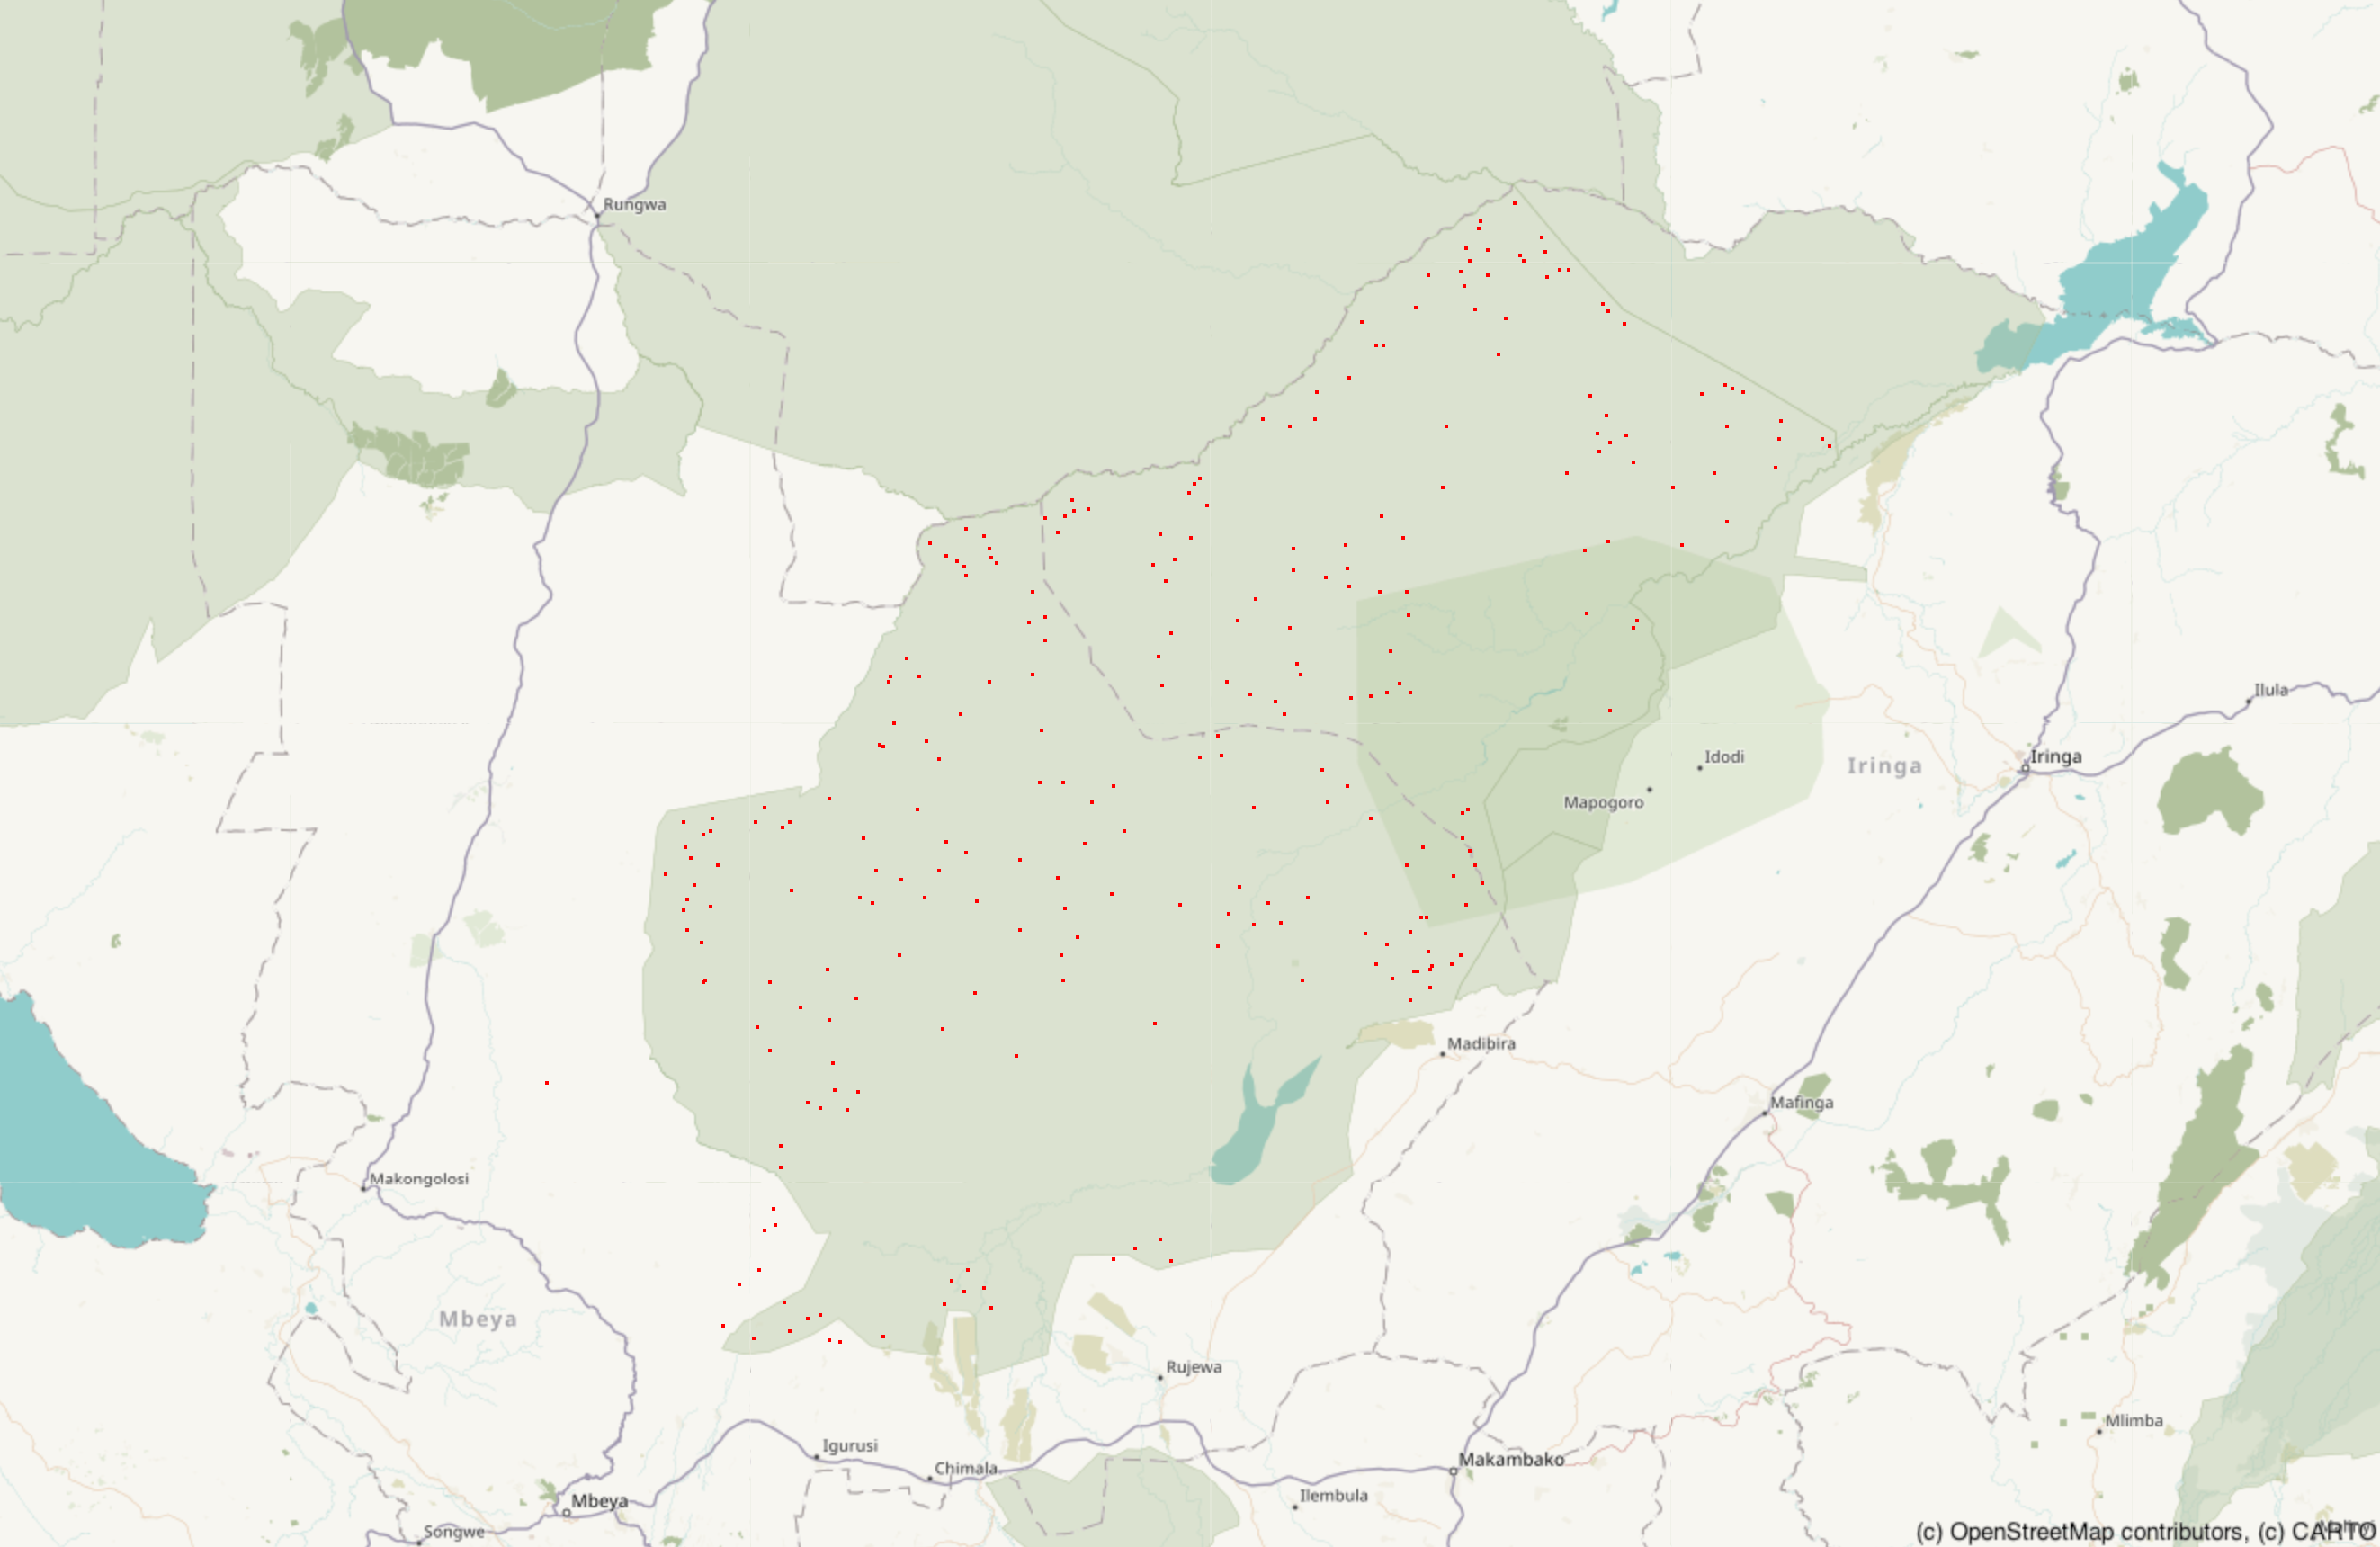

In [8]:
run_render('e801_dot.py', 'e801_dot_density')

### Step 07 - Visualise the density with the hist method and a binsize of 20

In [9]:
%%writefile e801_hist.py
import georender_tiles as gr
gr.setup_tiles('hot', 'tiles_hot')
import geoplotlib
from geoplotlib.utils import read_csv

dataset = read_csv('../../Datasets/poaching_points_cleaned.csv')

# plotting our dataset as a histogram
geoplotlib.hist(dataset, binsize=20)
geoplotlib.savefig('e801_histogram')

Overwriting e801_hist.py


2026-10-18 01:32:42.620 python[48730:19503494] +[IMKClient subclass]: chose IMKClient_Modern
2026-10-18 01:32:42.651 python[48730:19503494] +[IMKInputSession subclass]: chose IMKInputSession_Modern


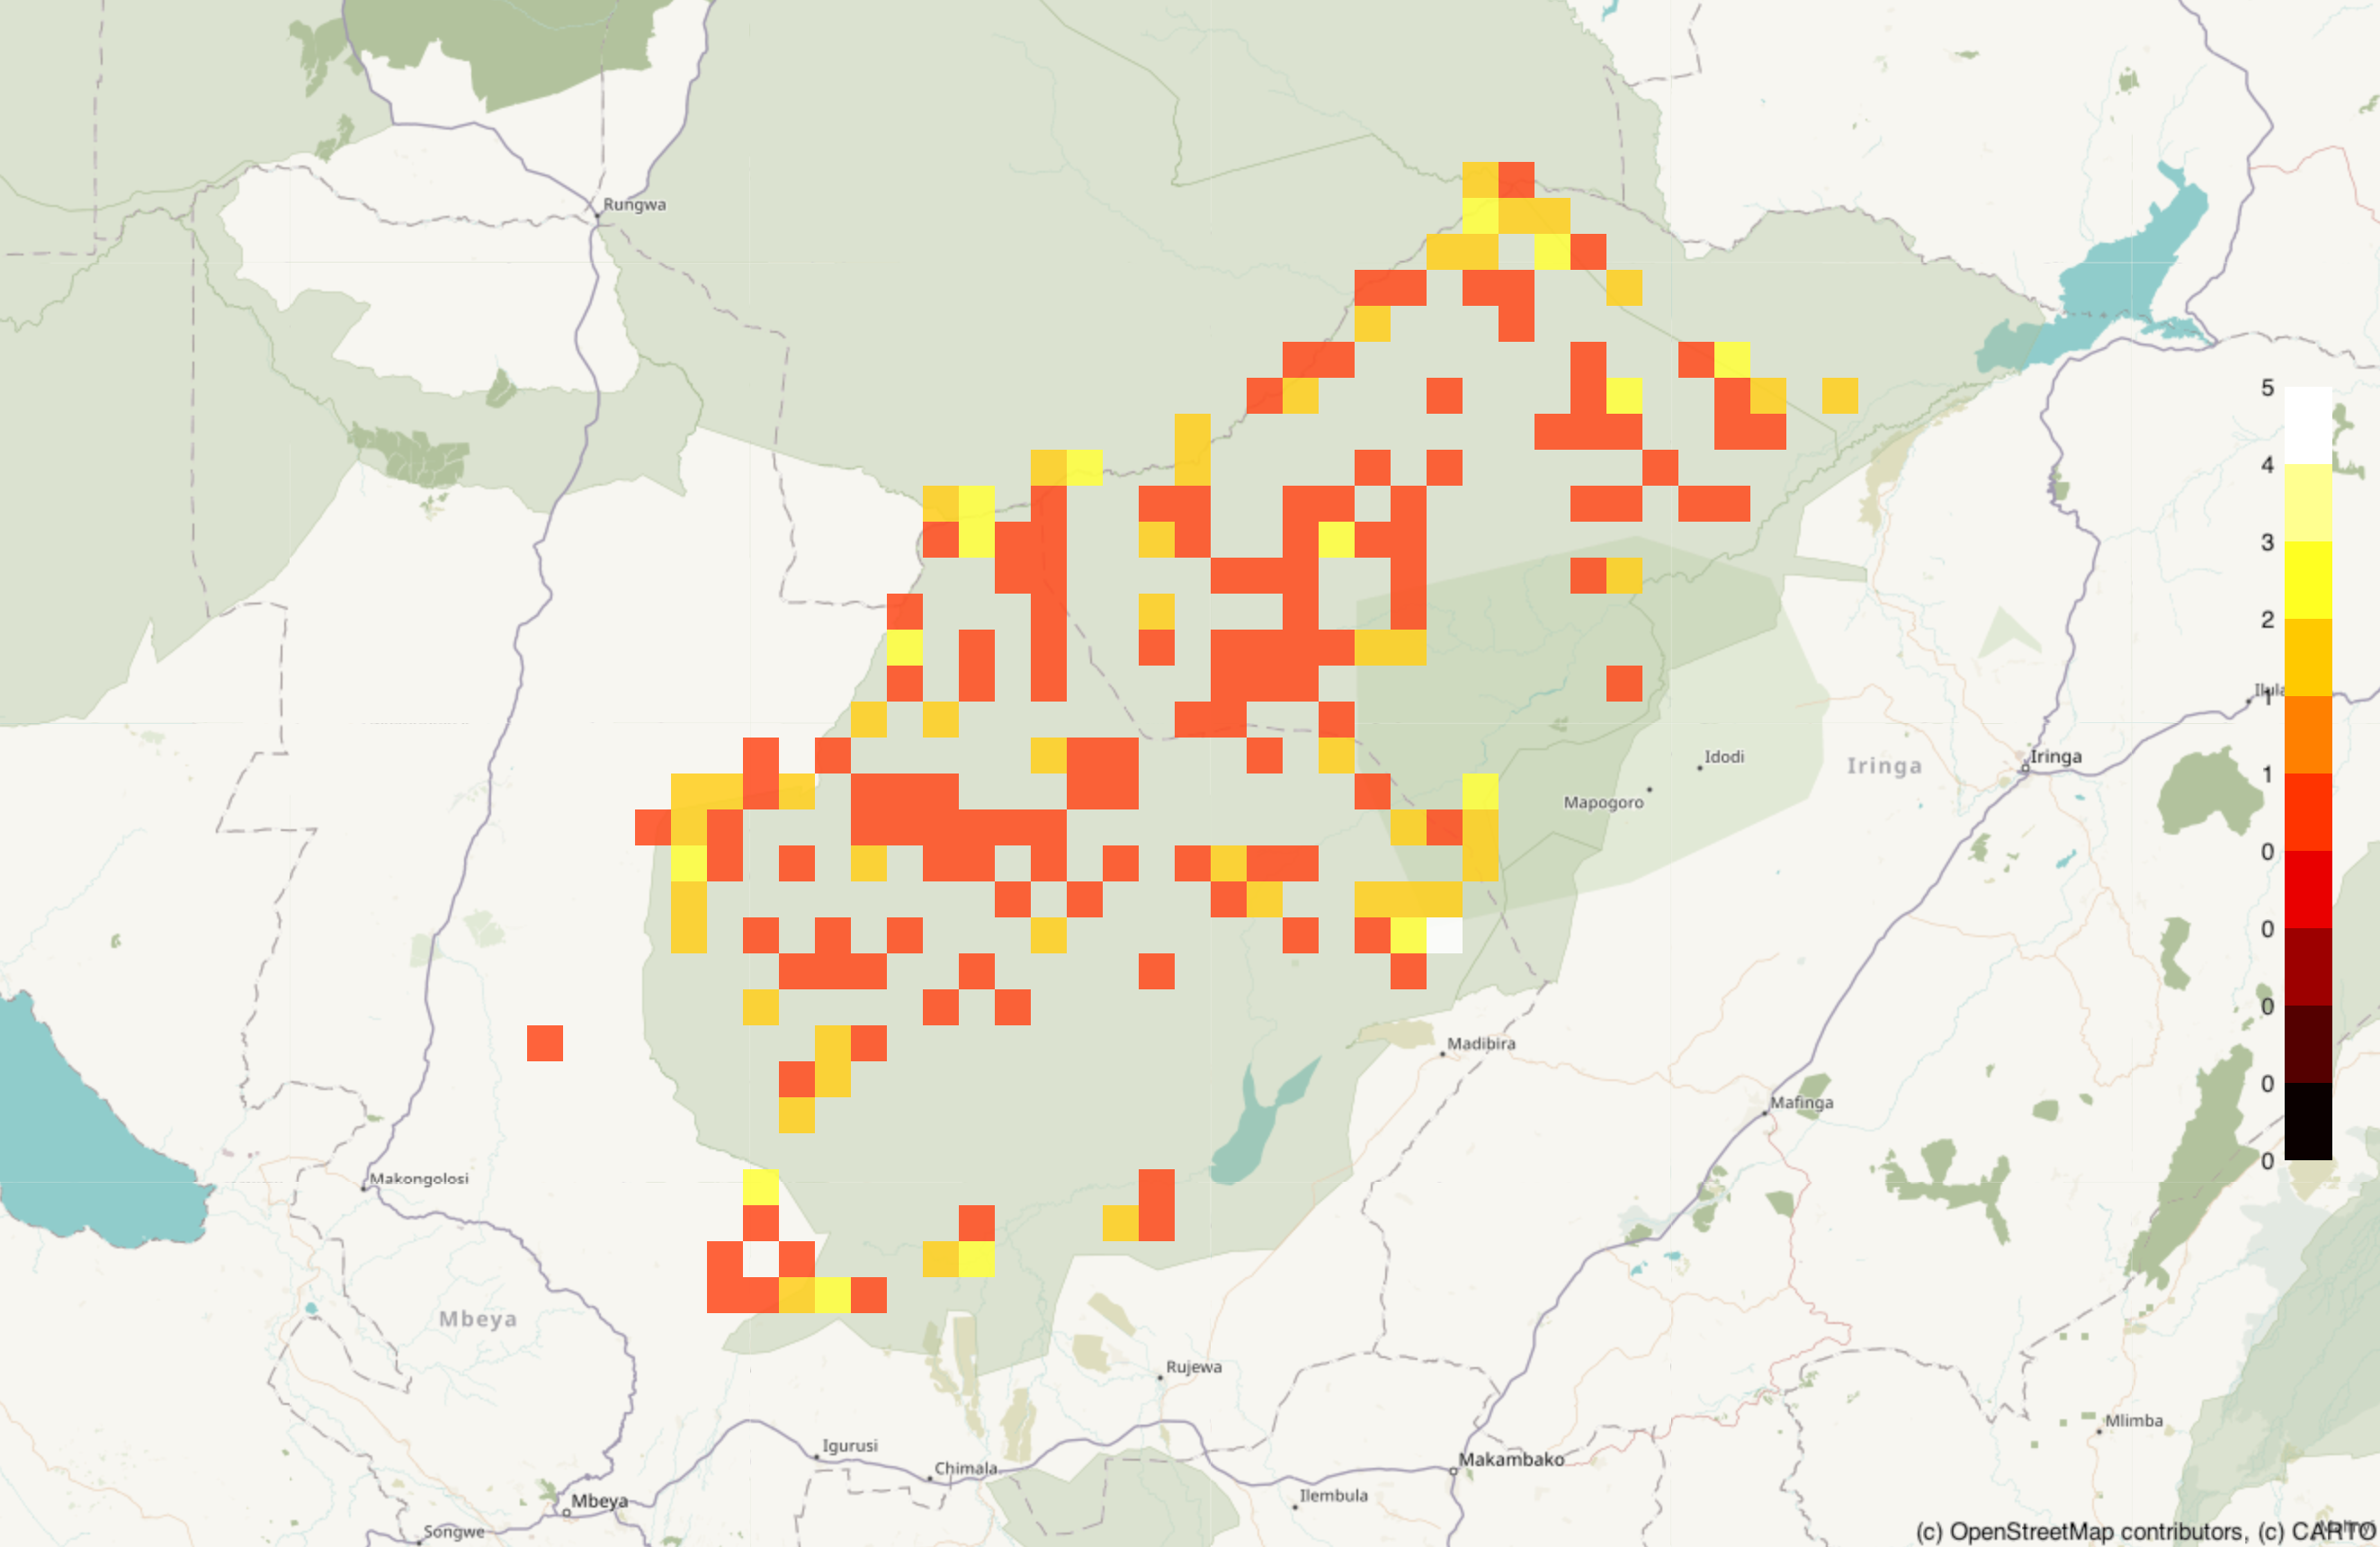

In [10]:
run_render('e801_hist.py', 'e801_histogram')

### Step 08 - Create a Voronoi plot with the colour map Blues_r and max_area 1e5

In [11]:
%%writefile e801_voronoi.py
import georender_tiles as gr
gr.setup_tiles('hot', 'tiles_hot')
import geoplotlib
from geoplotlib.utils import read_csv

dataset = read_csv('../../Datasets/poaching_points_cleaned.csv')

# plotting a voronoi map
geoplotlib.voronoi(dataset, cmap='Blues_r', max_area=1e5, alpha=255)
geoplotlib.savefig('e801_voronoi')

Overwriting e801_voronoi.py


2026-10-18 01:32:45.305 python[48738:19503579] +[IMKClient subclass]: chose IMKClient_Modern
2026-10-18 01:32:45.329 python[48738:19503579] +[IMKInputSession subclass]: chose IMKInputSession_Modern


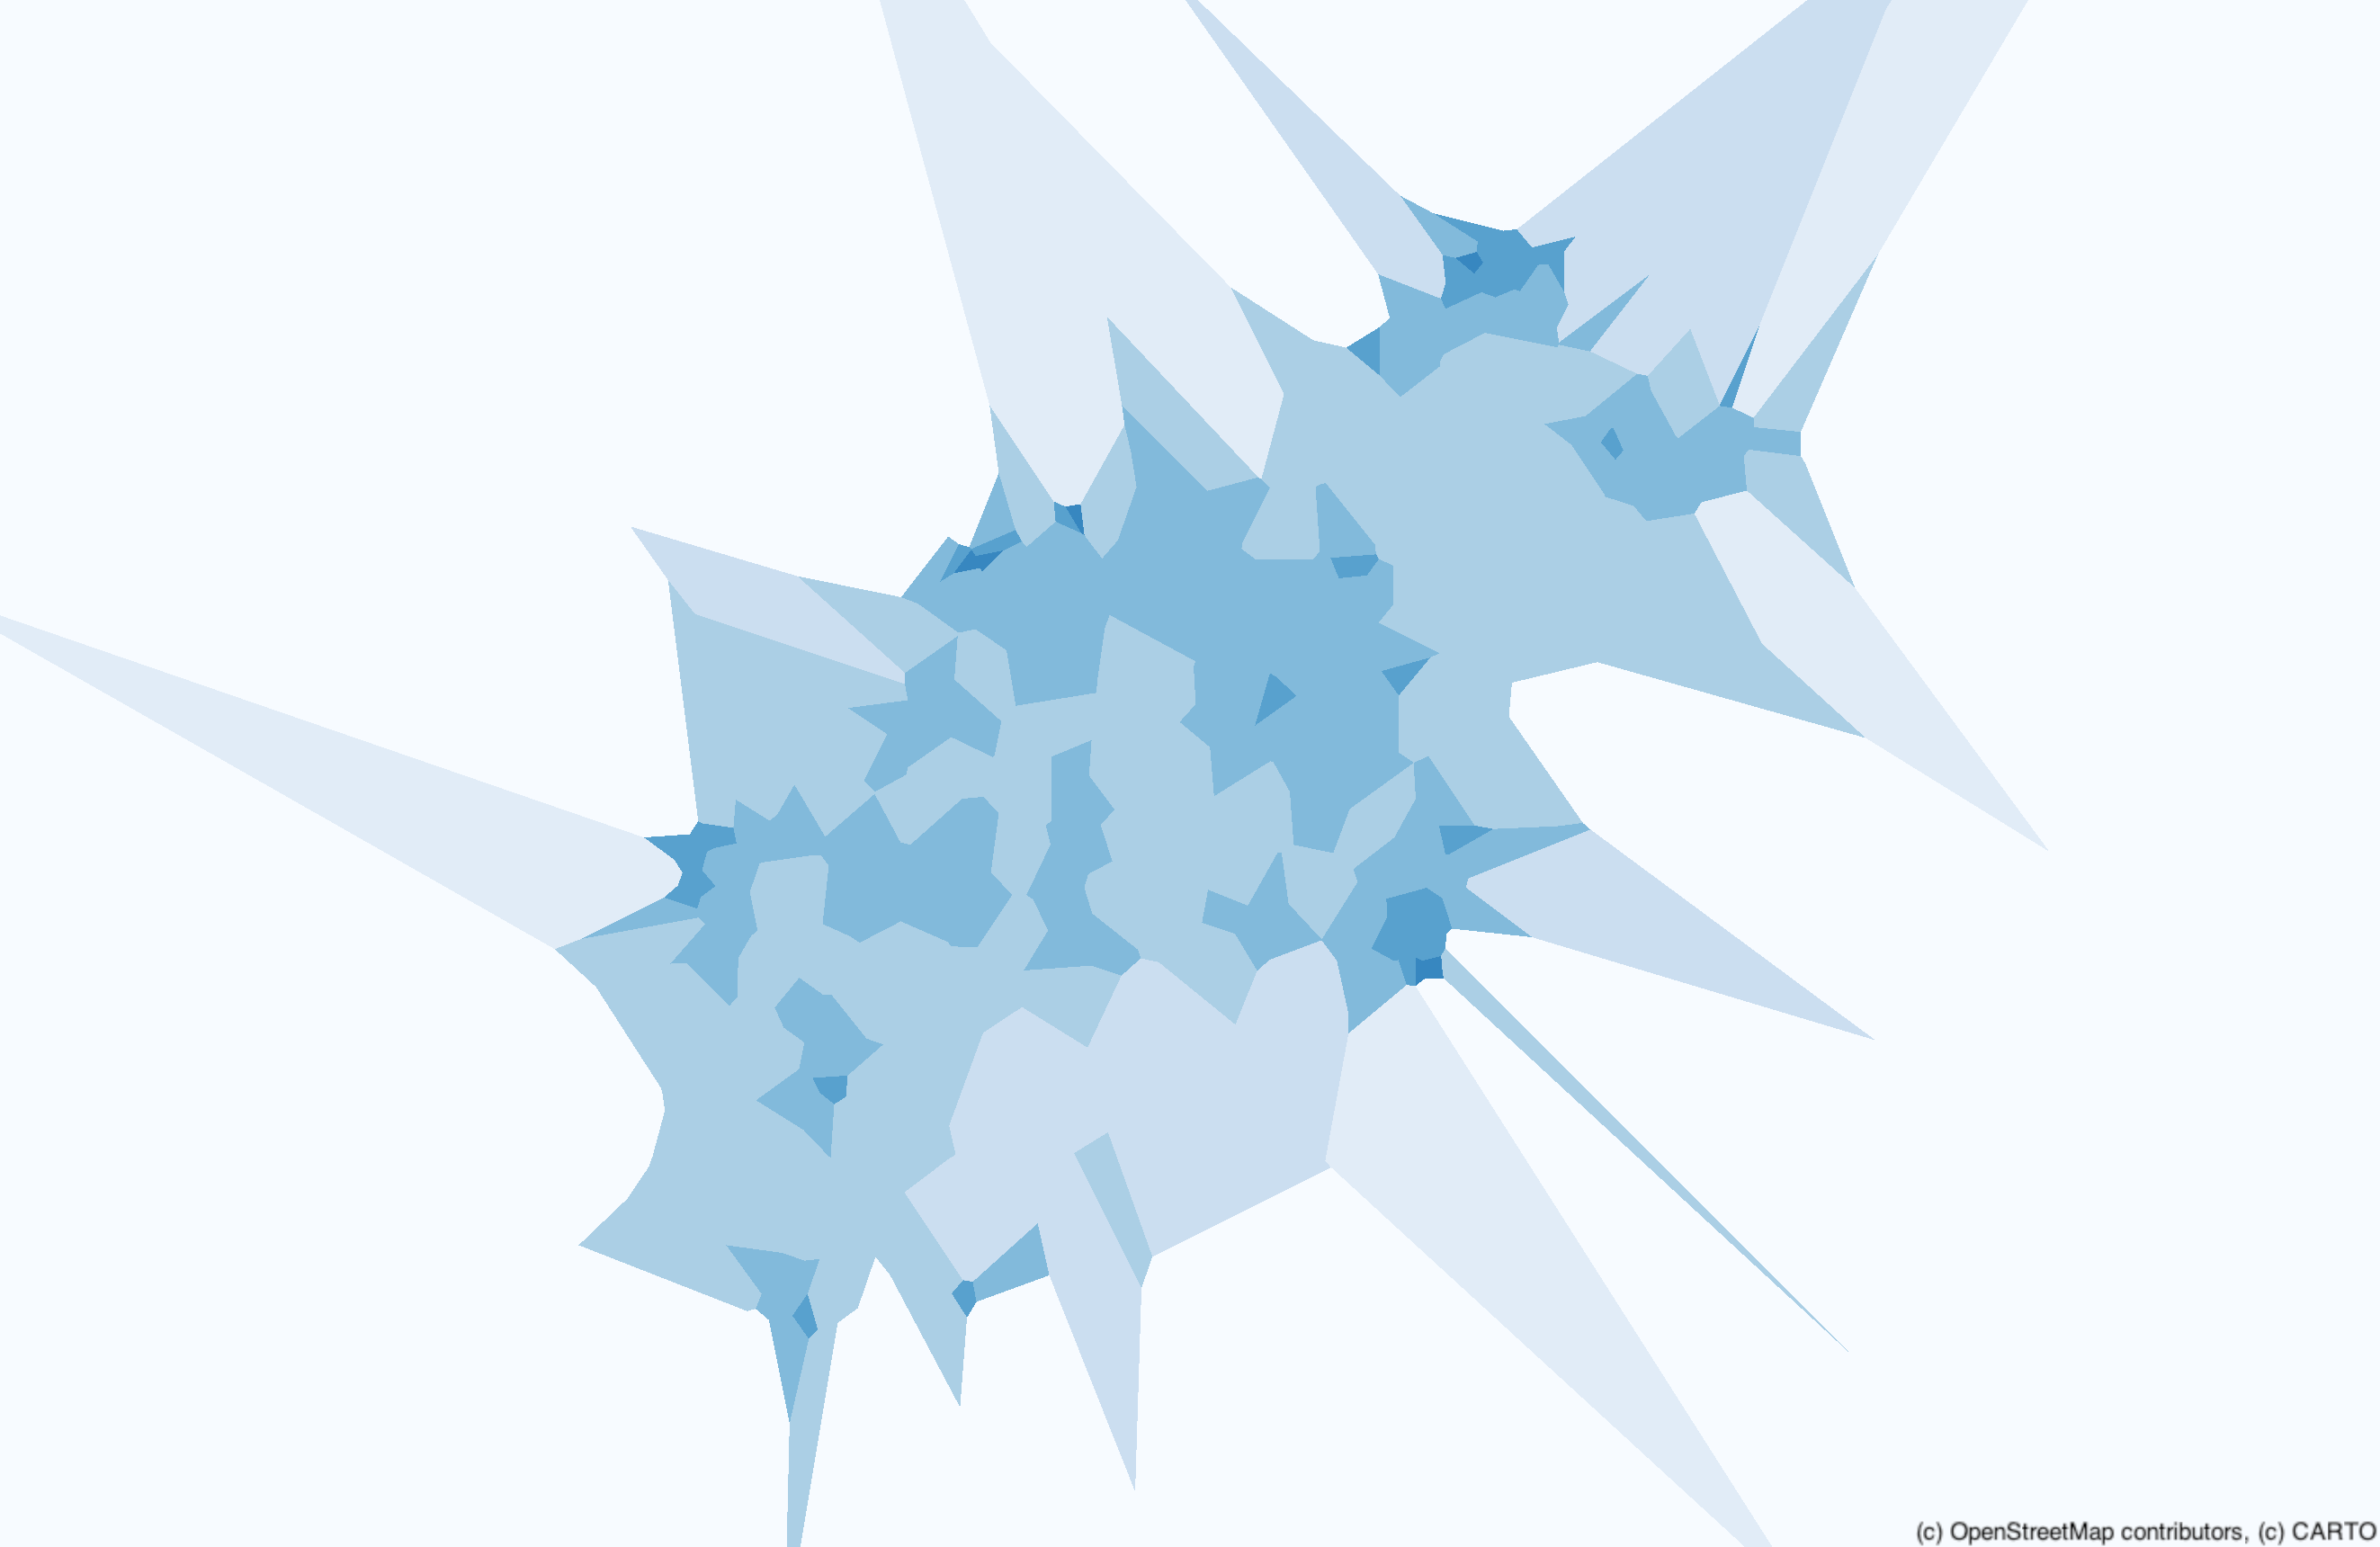

In [12]:
run_render('e801_voronoi.py', 'e801_voronoi')

OBSERVATION_PLACEHOLDER_801

### Step 09 - Save the notebook

This notebook is saved as `P1/Tutorial08/Exercise8.01.ipynb` and uploaded to the forum as `MC662722_Exercise8.01.ipynb`. It is also placed in `P1_folder/Jupyter Notebooks/` of the submitted archive `CISC3015-SugEx08-MC662722.zip`.